# FPL data split, benchmarks and evaluation

This notebook takes Notebook 2's player-fixture records and fixture calendar, assigns
chronological partitions, builds three pre-gameweek history features and saves a
validation report for four point benchmarks.

Recent-five points achieved the lowest 2024/25 validation RMSE at **2.1697 points**,
a **10.3%** improvement over the training-position mean across 27,283 recorded
player-fixtures. The [validation comparison](#compare-benchmark-errors) shows how the
benchmarks differ on absolute and squared errors.

## Data import

Notebook 2's player-fixture records and fixture calendar supply the inputs. Hashes identify
the input versions and confirm that this stage preserves them.

In [1]:
from pathlib import Path
from hashlib import sha256
import json
import os
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache/matplotlib"))

import numpy as np
import pandas as pd
from IPython.display import display

PROCESSED_DIR = PROJECT_ROOT / "data/processed"
MODEL_DIR = PROCESSED_DIR / "modelling"
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 30)
pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
from src.data_preparation import MATCH_KEY, PLAYER_KEY, require_keys
from src.model_preparation import (
    FEATURES, PREDICTIONS, RULE_VERSION, SEASON_SPLITS, benchmark_metrics, fit_benchmarks,
    historical_features, modelling_rows, predict_benchmarks,
    prediction_calendar, split_checks,
)

input_paths = [PROCESSED_DIR / name for name in
               ["fpl_eda_tables.pkl", "fpl_eda_manifest.json"]]
source_hashes = {path.name: sha256(path.read_bytes()).hexdigest() for path in input_paths}
tables = pd.read_pickle(input_paths[0])
eda_manifest = json.loads(input_paths[1].read_text())
display(pd.DataFrame([
    {"table": name, "rows": len(tables[name])}
    for name in ["player_matches", "fixtures", "current_events"]
]))

,table,rows
0,player_matches,119822
1,fixtures,1900
2,current_events,38


## Fix chronological partitions

| Partition | Seasons | Purpose |
|---|---|---|
| Train | 2022/23–2023/24 | Fit the benchmark means |
| Validation | 2024/25 | Compare frozen references and support development choices |
| Reserved test | 2025/26 | Evaluate the frozen forecasting procedure once |
| Monitor | Captured 2026/27 through GW10 | Keep later observations separate |

Complete fixtures and gameweeks stay together. Player histories reset each season
because the join uses season-scoped player IDs.

In [3]:
SPLIT_ORDER = ["train", "validation", "test", "monitor"]
RESULT_DELAY_HOURS = 24
partition_plan = pd.Series(SEASON_SPLITS, name="split").rename_axis("season").reset_index()
display(partition_plan)

,season,split
0,2022_2023,train
1,2023_2024,train
2,2024_2025,validation
3,2025_2026,test
4,2026_2027,monitor


## Establish the information cutoff

Forecasts use one cutoff per gameweek, including double gameweeks. The historical
proxy is the first recorded kickoff of the gameweek minus 24 hours. Captured 2026/27
fixtures use saved official FPL event deadlines.

Result availability is assumed to be kickoff plus 24 hours. A record is eligible
only if that timestamp is strictly before the target cutoff. Exact publication times,
prior fixture schedules and historical availability snapshots are absent. Final
corrections can differ from the values available at the time.

In [4]:
calendar = prediction_calendar(tables["fixtures"], tables["current_events"])
rows = modelling_rows(tables["player_matches"], tables["fixtures"], calendar)
require_keys(rows, MATCH_KEY, "partitioned player fixtures")
assert len(rows) == len(tables["player_matches"])
monitor_calendar = calendar.season.map(SEASON_SPLITS).eq("monitor")
assert calendar.loc[monitor_calendar, "cutoff_basis"].eq("saved_fpl_deadline").all()
assert calendar.loc[~monitor_calendar, "cutoff_basis"].eq(
    "first_kickoff_minus_24h_proxy",
).all()
cutoff_coverage = calendar.groupby(["season", "cutoff_basis"]).size().rename("gameweeks")
display(cutoff_coverage.to_frame())
display(calendar.loc[calendar.GW.eq(1), [
    "season", "GW", "prediction_cutoff", "first_kickoff", "cutoff_basis",
]].reset_index(drop=True))

,,gameweeks
season,cutoff_basis,
2022_2023,first_kickoff_minus_24h_proxy,37
2023_2024,first_kickoff_minus_24h_proxy,38
2024_2025,first_kickoff_minus_24h_proxy,38
2025_2026,first_kickoff_minus_24h_proxy,38
2026_2027,saved_fpl_deadline,10


,season,GW,prediction_cutoff,first_kickoff,cutoff_basis
0,2022_2023,1,2022-08-04 19:00:00+00:00,2022-08-05 19:00:00+00:00,first_kickoff_minus_24h_proxy
1,2023_2024,1,2023-08-10 19:00:00+00:00,2023-08-11 19:00:00+00:00,first_kickoff_minus_24h_proxy
2,2024_2025,1,2024-08-15 19:00:00+00:00,2024-08-16 19:00:00+00:00,first_kickoff_minus_24h_proxy
3,2025_2026,1,2025-08-14 19:00:00+00:00,2025-08-15 19:00:00+00:00,first_kickoff_minus_24h_proxy
4,2026_2027,1,2026-08-21 17:30:00+00:00,2026-08-21 19:00:00+00:00,saved_fpl_deadline


## Inspect split boundaries

One observed player-fixture supplies one target, including recorded zero-minute
entries. The modelling view uses historical `P_adj` and current official `P_off`.
The historical adjustment harmonises defensive rewards and reviewed corrections.
Historical bonus and assist definitions still vary. The cancelled 2022/23 gameweek has
no observed fixtures. The cohort consists of recorded observations only.
[Scoring and target policy](../docs/fpl_rules.md#adjusted-target-used-in-notebook-1)

In [5]:
split_summary = rows.groupby("split").agg(
    records=("points", "size"), seasons=("season", "nunique"),
    first_cutoff=("prediction_cutoff", "min"), last_cutoff=("prediction_cutoff", "max"),
    first_target=("kickoff_time", "min"), last_target=("kickoff_time", "max"),
).reindex(SPLIT_ORDER)
display(split_summary)
split_validation = split_checks(rows, RESULT_DELAY_HOURS)
display(split_validation)
assert split_validation.passed.all()

,records,seasons,first_cutoff,last_cutoff,first_target,last_target
split,,,,,,
train,56230,2,2022-08-04 19:00:00+00:00,2024-05-18 15:00:00+00:00,2022-08-05 19:00:00+00:00,2024-05-19 15:00:00+00:00
validation,27283,1,2024-08-15 19:00:00+00:00,2025-05-24 15:00:00+00:00,2024-08-16 19:00:00+00:00,2025-05-25 15:00:00+00:00
test,29747,1,2025-08-14 19:00:00+00:00,2026-05-23 15:00:00+00:00,2025-08-15 19:00:00+00:00,2026-05-24 15:00:00+00:00
monitor,6562,1,2026-08-21 17:30:00+00:00,2026-11-06 18:30:00+00:00,2026-08-21 19:00:00+00:00,2026-11-08 16:30:00+00:00


,check,passed
0,configured_season_assignment,True
1,one_split_per_fixture,True
2,one_split_per_gameweek,True
3,one_cutoff_per_gameweek,True
4,cutoff_precedes_target,True
5,finite_targets,True
6,train_results_before_validation,True
7,validation_results_before_test,True
8,test_results_before_monitor,True


## Build features from available history

For each player-fixture, use the player's same-season records available strictly
before the shared gameweek cutoff. Results from the target gameweek are excluded.
The two means use the same latest five eligible records, or all eligible records when
fewer than five exist. Recorded zero-minute entries count in the means and the count.

| Feature in input order | Calculation |
|---|---|
| `recent_points_5` | Mean points over the selected records |
| `recent_minutes_5` | Mean minutes over the selected records |
| `prior_records` | Count of all eligible records |

For example, five eligible returns of 2, 6, 0, 8 and 4 points in 90, 90, 0, 85 and
70 minutes give a feature vector of `[4.0, 67.0, 12]` when there are 12 eligible
records in total. For a player with no eligible records, both means are missing and
the count is zero.

The feature list is explicit. Position, native IDs and match-time club are metadata.
Prices, dated availability, supplied form and xP, full-season profiles and outcomes
from the target fixture stay outside the feature list. The subsequent fixture's
`points` is the regression target.

In [6]:
features = historical_features(rows, result_delay_hours=RESULT_DELAY_HOURS)
has_history = features.history_available_at.notna()
pd.testing.assert_frame_equal(rows[MATCH_KEY], features[MATCH_KEY])
same_week = features.groupby(PLAYER_KEY + ["GW"])[FEATURES].nunique(dropna=False)
feature_validation = pd.DataFrame([
    {"check": "history_strictly_before_cutoff", "passed": features.loc[
        has_history, "history_available_at"
    ].lt(features.loc[has_history, "prediction_cutoff"]).all()},
    {"check": "target_fixture_excluded", "passed": ~features.loc[
        has_history, "history_fixture_id"
    ].eq(features.loc[has_history, "fpl_fixture_id"]).any()},
    {"check": "same_gameweek_features_frozen", "passed": same_week.le(1).all().all()},
    {"check": "all_source_rows_preserved", "passed": len(features) == len(rows)},
])
history_checks = pd.DataFrame([
    {"check": "target_gameweek_excluded", "passed": features.loc[
        has_history, "history_GW"
    ].ne(features.loc[has_history, "GW"]).all()},
    {"check": "prior_count_matches_history", "passed": features.prior_records.gt(0).eq(
        has_history
    ).all()},
    {"check": "means_missing_only_at_cold_start", "passed": features[
        ["recent_points_5", "recent_minutes_5"]
    ].isna().eq(~has_history, axis="index").all().all()},
])
all_feature_checks = pd.concat([feature_validation, history_checks], ignore_index=True)
display(all_feature_checks)
assert all_feature_checks.passed.all()

,check,passed
0,history_strictly_before_cutoff,True
1,target_fixture_excluded,True
2,same_gameweek_features_frozen,True
3,all_source_rows_preserved,True
4,target_gameweek_excluded,True
5,prior_count_matches_history,True
6,means_missing_only_at_cold_start,True


## Inspect the evidence for individual forecasts

The trace shows the newest source fixture and its assumed availability time. With a fixed
delay, all earlier records used in the window were available by that timestamp. Cold
starts appear with missing means and zero prior records. The recent-five benchmark uses
the fitted training-position mean in those cases.

In [7]:
trace_columns = ["name", "GW", "fpl_fixture_id", "prediction_cutoff",
                 "history_fixture_id", "history_available_at", *FEATURES]
validation_mask = features.split.eq("validation")
trace = pd.concat([
    features.loc[validation_mask & ~has_history].head(2),
    features.loc[validation_mask & has_history].head(4),
])
display(trace[trace_columns].reset_index(drop=True))
display(features.groupby("split").agg(
    records=("points", "size"),
    without_history=("history_available_at", lambda values: values.isna().sum()),
).reindex(SPLIT_ORDER))

,name,GW,fpl_fixture_id,prediction_cutoff,history_fixture_id,history_available_at,recent_points_5,recent_minutes_5,prior_records
0,Fábio Ferreira Vieira,1,2,2024-08-15 19:00:00+00:00,<NA>,NaT,NaN,NaN,0
1,Gabriel Fernando de Jesus,1,2,2024-08-15 19:00:00+00:00,<NA>,NaT,NaN,NaN,0
2,Fábio Ferreira Vieira,2,11,2024-08-23 11:30:00+00:00,2,2024-08-18 14:00:00+00:00,0.0000,0.0000,1
3,Gabriel Fernando de Jesus,2,11,2024-08-23 11:30:00+00:00,2,2024-08-18 14:00:00+00:00,0.0000,5.0000,1
4,Gabriel dos Santos Magalhães,2,11,2024-08-23 11:30:00+00:00,2,2024-08-18 14:00:00+00:00,6.0000,90.0000,1
5,Kai Havertz,2,11,2024-08-23 11:30:00+00:00,2,2024-08-18 14:00:00+00:00,12.0000,90.0000,1


,records,without_history
split,,
train,56230,1678
validation,27283,791
test,29747,844
monitor,6562,672


## Fit benchmark references on training records

Compare four point forecasts on the same recorded 2024/25 player-fixtures. The zero
reference always predicts zero. The training mean and training-position mean use only
training targets. Recent-five predicts the mean of the latest eligible points and uses
the training-position mean for a cold start. An unseen position falls back to the
overall training mean.

Earlier validation results can update later histories after the availability delay.
The fitted means remain fixed throughout validation.

In [8]:
train = features.loc[features.split.eq("train")].copy()
validation = features.loc[validation_mask].copy()
fitted = fit_benchmarks(train)
validation_predictions = predict_benchmarks(validation, fitted)
display(pd.Series(fitted["position_mean"], name="training_mean_points").to_frame())
display(validation_predictions[["name", "GW", "points", *PREDICTIONS]].head(8))
pd.testing.assert_frame_equal(validation[MATCH_KEY], validation_predictions[MATCH_KEY])
assert validation_predictions.split.eq("validation").all()
assert validation_predictions[PREDICTIONS].notna().all().all()

,training_mean_points
DEF,1.1358
FWD,1.2918
GK,0.8472
MID,1.3417


,name,GW,points,zero,train_mean,train_position_mean,recent_five
56230,Fábio Ferreira Vieira,1,0.0000,0.0000,1.2121,1.3417,1.3417
56231,Gabriel Fernando de Jesus,1,0.0000,0.0000,1.2121,1.2918,1.2918
56232,Gabriel dos Santos Magalhães,1,6.0000,0.0000,1.2121,1.1358,1.1358
56233,Kai Havertz,1,12.0000,0.0000,1.2121,1.2918,1.2918
56234,Karl Hein,1,0.0000,0.0000,1.2121,0.8472,0.8472
56235,Jurriën Timber,1,1.0000,0.0000,1.2121,1.1358,1.1358
56236,Jorge Luiz Frello Filho,1,0.0000,0.0000,1.2121,1.3417,1.3417
56237,Jakub Kiwior,1,0.0000,0.0000,1.2121,1.1358,1.1358


## Challenge the temporal boundary

Perturb points and minutes in the final validation cutoff block and both later
partitions. Training and validation features, fitted means and validation forecasts
must be identical. This checks isolation from later partitions and from target-gameweek
outcomes at the final validation cutoff.

In [9]:
changed = rows.copy()
last_validation_cutoff = validation.prediction_cutoff.max()
last_validation_block = validation_mask & rows.prediction_cutoff.eq(last_validation_cutoff)
changed_rows = last_validation_block | rows.split.isin(["test", "monitor"])
changed.loc[changed_rows, "points"] += 1000
changed.loc[changed_rows, "minutes"] += 90

challenged = historical_features(changed, result_delay_hours=RESULT_DELAY_HOURS)
development = features.split.isin(["train", "validation"])
pd.testing.assert_frame_equal(
    features.loc[development, MATCH_KEY + FEATURES],
    challenged.loc[development, MATCH_KEY + FEATURES],
)
assert fitted == fit_benchmarks(challenged.loc[challenged.split.eq("train")])
challenged_predictions = predict_benchmarks(challenged.loc[validation_mask], fitted)
pd.testing.assert_frame_equal(
    validation_predictions[PREDICTIONS], challenged_predictions[PREDICTIONS],
)
display(pd.DataFrame([{"check": "target_and_future_outcome_perturbation", "passed": True}]))

,check,passed
0,target_and_future_outcome_perturbation,True


## Save modelling inputs

The export keeps native player-fixture keys and stores development, reserved test and
monitoring rows in separate tables alongside the cutoff calendar. Input hashes and the
timing policy accompany the saved artifacts. Forecasts in the benchmark export cover
validation only.

In [10]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_data = {
    "development": features.loc[development].copy(),
    "reserved_test": features.loc[features.split.eq("test")].copy(),
    "monitor": features.loc[features.split.eq("monitor")].copy(), "calendar": calendar,
}
model_audits = {"split": split_validation, "features": feature_validation,
                "split_summary": split_summary, "benchmark_parameters": fitted}
pd.to_pickle(model_data, MODEL_DIR / "fpl_model_data.pkl")
pd.to_pickle(validation_predictions, MODEL_DIR / "fpl_benchmark_predictions.pkl")
pd.to_pickle(model_audits, MODEL_DIR / "fpl_split_audits.pkl")

In [11]:
artifact_names = ["fpl_model_data.pkl", "fpl_benchmark_predictions.pkl", "fpl_split_audits.pkl"]
manifest = {
    "schema_version": RULE_VERSION, "created_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "input_sha256": source_hashes, "eda_schema": eda_manifest["schema_version"],
    "code_sha256": sha256((PROJECT_ROOT / "src/model_preparation.py").read_bytes()).hexdigest(),
    "split_seasons": SEASON_SPLITS, "features": FEATURES, "target": "points",
    "target_policy": "historical P_adj; current P_off",
    "historical_cutoff": "first recorded gameweek kickoff minus 24h; proxy",
    "current_cutoff": "saved FPL event deadline", "result_delay_hours": RESULT_DELAY_HOURS,
    "evaluation": "rolling gameweek forecasts; frozen training references",
    "test_scored": False, "manager_average": "deferred to squad-level evaluation",
    "artifacts_sha256": {name: sha256((MODEL_DIR / name).read_bytes()).hexdigest()
                         for name in artifact_names},
}
(MODEL_DIR / "fpl_model_manifest.json").write_text(json.dumps(manifest, indent=2))
assert source_hashes == {path.name: sha256(path.read_bytes()).hexdigest() for path in input_paths}
display(pd.DataFrame([{"partition": key, "records": len(frame)}
                      for key, frame in model_data.items() if key != "calendar"]))

,partition,records
0,development,83513
1,reserved_test,29747
2,monitor,6562


## Error definitions

Validation RMSE is the primary comparison metric. It weights large errors more heavily
than MAE, the mean absolute error. Signed bias is the mean of prediction minus outcome,
so negative bias indicates underprediction on average. All three metrics use
player-fixture points.

In [12]:
predictions = validation_predictions
scores = benchmark_metrics(predictions)
display(scores.sort_values("RMSE").reset_index(drop=True))
position_scores = benchmark_metrics(predictions, by=("position",))
display(position_scores.pivot(index="position", columns="model", values="RMSE").reindex(
    ["GK", "DEF", "MID", "FWD"],
))

,model,records,MAE,RMSE,bias
0,recent_five,27283,1.1211,2.1697,0.0030
1,train_position_mean,27283,1.5599,2.4194,-0.0236
2,train_mean,27283,1.5649,2.4242,-0.0266
3,zero,27283,1.2505,2.7223,-1.2388


model,recent_five,train_mean,train_position_mean,zero
position,,,,
GK,1.7608,2.0760,2.0509,2.2343
DEF,2.1387,2.3256,2.3248,2.5940
MID,2.2147,2.4897,2.4855,2.8320
FWD,2.4167,2.7350,2.7319,3.0499


## Compare benchmark errors

All bars cover the same validation records. The comparison separates typical absolute error
from sensitivity to larger point returns.

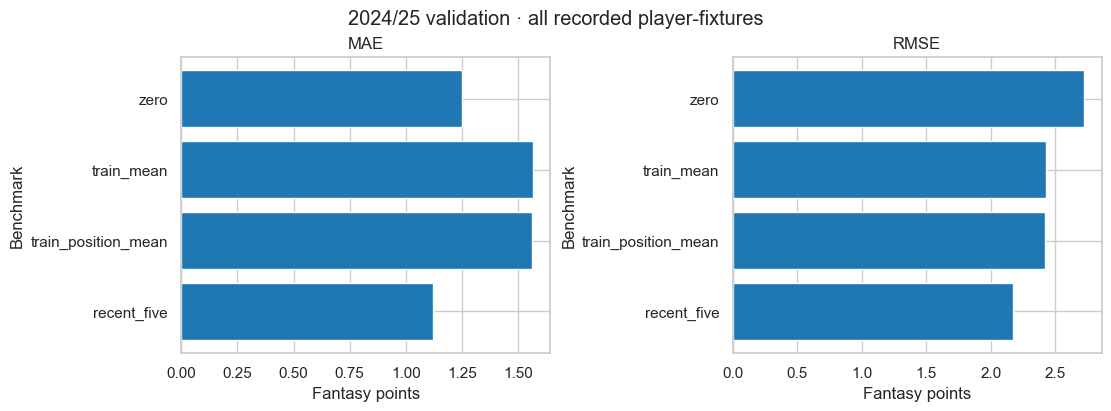

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
ordered = scores.set_index("model").reindex(PREDICTIONS)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    ax.barh(ordered.index, ordered[metric], color="tab:blue")
    ax.set(title=metric, xlabel="Fantasy points", ylabel="Benchmark")
    ax.invert_yaxis()
fig.suptitle("2024/25 validation · all recorded player-fixtures")
plt.show()

## Variation across gameweeks

Gameweek RMSE compares the four benchmarks across the season. Each value covers all
recorded player-fixtures in that gameweek, including both fixtures for players with
a double.

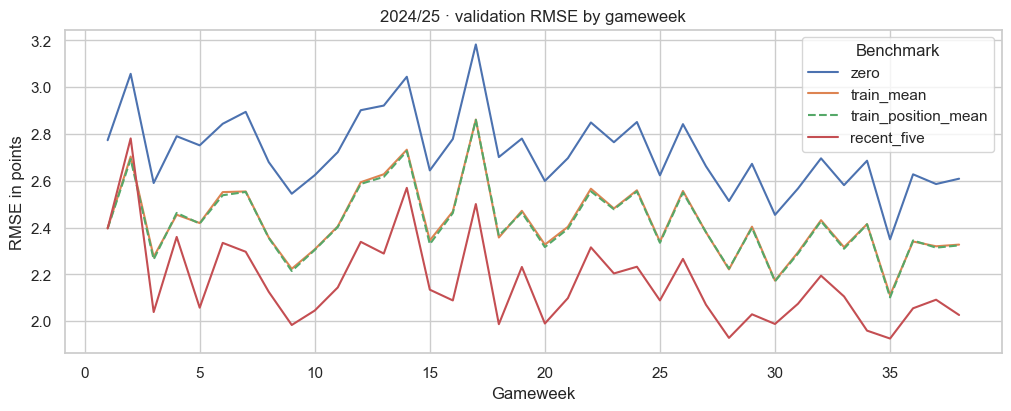

In [14]:
gameweek_scores = benchmark_metrics(predictions, by=("GW",))
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for model in PREDICTIONS:
    frame = gameweek_scores.loc[gameweek_scores.model.eq(model)]
    style = "--" if model == "train_position_mean" else "-"
    ax.plot(frame.GW, frame.RMSE, linestyle=style, label=model, linewidth=1.5)
ax.set(title="2024/25 · validation RMSE by gameweek", xlabel="Gameweek", ylabel="RMSE in points")
ax.legend(title="Benchmark")
plt.show()

## Inspect large misses and participation

The largest recent-five misses show how exceptional returns affect error. The
positive-minute subset provides a supplementary diagnostic. The primary validation
comparison uses every observed record.

In [15]:
errors = predictions.assign(recent_error=predictions.recent_five - predictions.points)
display(errors.loc[errors.recent_error.abs().nlargest(8).index, [
    "name", "GW", "position", "minutes", "points", "recent_five", "recent_error",
]].reset_index(drop=True))
appearance_scores = benchmark_metrics(predictions.loc[predictions.minutes.gt(0)])
display(appearance_scores.sort_values("RMSE").reset_index(drop=True))

,name,GW,position,minutes,points,recent_five,recent_error
0,Kevin Schade,13,MID,69,23.0000,1.0000,-22.0000
1,Noni Madueke,2,MID,90,20.0000,0.0000,-20.0000
2,Cole Palmer,6,MID,90,25.0000,7.2000,-17.8000
3,Justin Kluivert,22,MID,90,22.0000,4.2000,-17.8000
4,Dango Ouattara,23,MID,90,21.0000,3.6000,-17.4000
5,Matthijs de Ligt,4,DEF,86,17.0000,0.6667,-16.3333
6,Dean Huijsen,14,DEF,90,17.0000,0.8000,-16.2000
7,Michail Antonio,7,FWD,69,18.0000,2.0000,-16.0000


,model,records,MAE,RMSE,bias
0,recent_five,11567,2.1787,3.1679,-0.4556
1,train_position_mean,11567,2.0489,3.4370,-1.6860
2,train_mean,11567,2.0440,3.4446,-1.7098
3,zero,11567,2.9494,4.1808,-2.9219


## Check cold-start behaviour

Players without available same-season histories receive the frozen training position mean.
The table distinguishes those predictions from forecasts supported by prior observations.

In [16]:
coverage = predictions.assign(
    history_group=np.where(predictions.prior_records.eq(0), "No prior records", "Prior records"),
)
display(benchmark_metrics(coverage, by=("history_group",)).query(
    "model == 'recent_five'"
).reset_index(drop=True))
reference = scores.set_index("model")
improvement = 1 - (
    reference.loc["recent_five", "RMSE"] / reference.loc["train_position_mean", "RMSE"]
)
print(f"Recent-five RMSE improvement over position mean: {improvement:.1%}")

,history_group,model,records,MAE,RMSE,bias
0,No prior records,recent_five,791,1.4719,2.2073,0.0397
1,Prior records,recent_five,26492,1.1106,2.1686,0.0019


Recent-five RMSE improvement over position mean: 10.3%


## Save validation results

These exports contain development diagnostics only. The split manifest continues to record
an unscored test partition.

In [17]:
evaluation = {
    "overall": scores, "position": position_scores, "gameweek": gameweek_scores,
    "appearances": appearance_scores,
}
pd.to_pickle(evaluation, MODEL_DIR / "fpl_benchmark_evaluation.pkl")
split_manifest_path = MODEL_DIR / "fpl_model_manifest.json"
evaluation_manifest = {
    "created_at_utc": pd.Timestamp.now(tz="UTC").isoformat(), "scored_split": "validation",
    "split_manifest_sha256": sha256(split_manifest_path.read_bytes()).hexdigest(),
    "models": PREDICTIONS, "test_scored": False,
}
(MODEL_DIR / "fpl_evaluation_manifest.json").write_text(json.dumps(evaluation_manifest, indent=2))
assert predictions.split.eq("validation").all()
assert not manifest["test_scored"]

## Preparation and evaluation summary

The split and feature checks passed, including frozen double-gameweek histories,
cold-start handling and the outcome perturbation. Recent-five led on validation RMSE
overall and in all four positions. The zero reference had lower MAE than both static
training means, which shows why the metric matters for this sparse target.

The 2025/26 test season was used for descriptive EDA and remains reserved for the
final predictive evaluation. The captured 2026/27 monitoring records also remain
unscored. Average FPL manager points belong to a separate squad-level comparison
that accounts for captaincy, substitutions, chips and transfers.